# Flame sensor processing: what the vote buys and what it cannot

**A study of the rules, on simulated signals.** The box reads a flame module (KY-026) at each wake-up. This notebook explains the processing applied to those reads, and measures what each rule does to false triggers and to the detection delay.

**Abstract.** One wake-up gives a burst of $n=8$ digital reads. The processing (1) fixes the polarity, (2) takes a majority vote ($\ge 5$ of 8), and (3) counts the transitions of the burst. The state machine then asks for two positive wake-ups in a row before it opens a suspicion. We show, by an exact binomial formula checked by simulation, how the vote suppresses isolated glitches; how the two-wake-up rule sets the delay of a real flame, and how a 30 s recheck after a first positive read shortens it at the price of more sensitivity to reflections; and why a steady light (sun) cannot be rejected by the vote.

**Data caveat, first.** **No recording of the KY-026 exists in this project.** Glitch rates, sunlight behaviour and flame flicker below are *models with assumed parameters*, not measurements. What is solid is the arithmetic of the rules (probabilities, timing); what is not is how often the real module behaves like the model. Every number tagged *model* must be re-measured on the module.

In [1]:
import sys, math, random
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../src"); sys.path.insert(0, "../../../state_machine/python/src")
from flame import Config, process
from flame.synthetic import clean_burst, steady_burst, flame_burst
from state_machine import StateMachine, Inputs, NORMAL, SUSPICION, Config as StateMachineConfig

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
CFG = Config()
print(CFG)

Config(active_low=True, burst_samples=8, vote_ratio=0.625, flicker_min=0)


## 1. The three stages on example bursts

A KY-026 module pulls its digital output (DO) low when it sees a flame (*active low*, to be checked on the module). A raw read of `0` is therefore a positive read. With $a_i\in\{0,1\}$ the positive reads of a burst of length $n$:

$$ s=\sum_{i=1}^{n} a_i,\qquad \text{vote}= \left[\, s \ge \rho\, n \,\right],\qquad \tau=\sum_{i=2}^{n}\mathbb 1[a_i\neq a_{i-1}], $$

with $\rho=0.625$ (5 of 8). $\tau$ counts the transitions (flicker). The optional rule $\tau\ge\tau_{\min}$ is off ($\tau_{\min}=0$).

In [2]:
examples = {
    "dark": [1]*8,
    "1 glitch": [1,1,1,0,1,1,1,1],
    "4 of 8": [0,0,0,0,1,1,1,1],
    "5 of 8": [0,0,0,0,0,1,1,1],
    "steady (sun)": [0]*8,
    "flickering flame": [0,0,1,0,0,1,0,0],
}
print(f"{'burst':18s} {'raw reads':20s} {'ratio':>6s} {'trans.':>6s} {'detected':>9s}")
for name, raw in examples.items():
    r = process(raw)
    print(f"{name:18s} {''.join(map(str, raw)):20s} {r.ratio:6.3f} {r.transitions:6d} {str(r.detected):>9s}")

burst              raw reads             ratio trans.  detected
dark               11111111              0.000      0     False
1 glitch           11101111              0.125      2     False
4 of 8             00001111              0.500      1     False
5 of 8             00000111              0.625      1      True
steady (sun)       00000000              1.000      0      True
flickering flame   00100100              0.750      4      True


**Reading.** A lone glitch (1 of 8) and a half-lit burst (4 of 8) are rejected; the limit is exactly 5 of 8. A steady light (8 of 8) is accepted with 0 transitions: the vote cannot tell it from a flame. This is the structural limit of the block (section 5).

## 2. What the vote does to single-read glitches

Model: each read of a dark scene is wrongly positive with probability $p$, independently. The burst is positive when at least $k=\lceil\rho n\rceil$ reads are:

$$ b(p)=\sum_{j=k}^{n}\binom{n}{j}p^j(1-p)^{n-j}. $$

We check the formula against the code (`process`) on simulated bursts.

     p   formula b(p)    simulated  |diff|/SE
  0.05       0.000015     0.000007       1.22
  0.10       0.000432     0.000383       1.27
  0.20       0.010406     0.010217       1.02
  0.30       0.057968     0.058097       0.30
  0.50       0.363281     0.361820       1.66


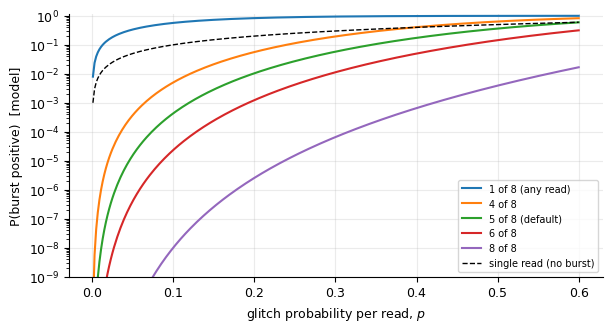

In [3]:
def b_exact(p, n=8, rho=0.625):
    k = math.ceil(rho * n - 1e-12)
    return sum(math.comb(n, j) * p**j * (1-p)**(n-j) for j in range(k, n+1))

rng = random.Random(1)
print(f"{'p':>6s} {'formula b(p)':>14s} {'simulated':>12s} {'|diff|/SE':>10s}")
N = 300_000
for p in (0.05, 0.1, 0.2, 0.3, 0.5):
    sim = sum(process(clean_burst(8, p, rng)).detected for _ in range(N)) / N
    ex = b_exact(p)
    se = math.sqrt(ex * (1-ex) / N)
    print(f"{p:6.2f} {ex:14.6f} {sim:12.6f} {abs(sim-ex)/se:10.2f}")

ps = np.linspace(0.001, 0.6, 300)
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for rho, lab in ((1/8, "1 of 8 (any read)"), (0.5, "4 of 8"), (0.625, "5 of 8 (default)"), (0.75, "6 of 8"), (1.0, "8 of 8")):
    ax.plot(ps, [b_exact(p, 8, rho) for p in ps], label=lab)
ax.plot(ps, ps, "k--", lw=1, label="single read (no burst)")
ax.set_yscale("log"); ax.set_ylim(1e-9, 1.2); ax.set_xlabel("glitch probability per read, $p$")
ax.set_ylabel("P(burst positive)  [model]"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

**Reading.** The formula and the code agree within 1.7 standard errors at the five values tested (for the two rare cases, $p=0.05$ and $0.1$, the normal approximation of the error is poor, but the values are tiny). The curves show the effect: at $p=0.1$ per read, a single read is positive 10 % of the time, the 5-of-8 vote 0.04 % of the time. Raising the ratio to 6 of 8 or 8 of 8 suppresses more glitches but also loses a flame whose output flickers (section 6). **Model:** independent glitches; real glitches (electrical noise, a failing comparator, sun) are probably correlated, which makes the vote less effective than shown.

## 3. From glitches to false suspicions per day

The state machine opens a suspicion after **two consecutive positive wake-ups**. With a burst-positive probability $b$ and $W$ wake-ups per day, the expected number of false suspicions is about $W\,b^2$. Eco mode wakes every 300 s ($W=288$), Alert mode every 30 s ($W=2880$). We compare a single read per wake-up with the 5-of-8 vote, by simulating the real state machine (flame input only, no gas).

In [4]:
def false_suspicions(p, n, rho, wake_s, days, seed):
    """Entries into Suspicion per day, flame input only, dark scene with glitch probability p per read."""
    rng = random.Random(seed)
    cfg = Config(vote_ratio=rho)
    sm = StateMachine()
    wakes = int(days * 86400 / wake_s)
    entries, prev = 0, NORMAL
    for _ in range(wakes):
        flame = process(clean_burst(n, p, rng), cfg).detected
        out = sm.step(Inputs(flame=flame, dt_s=wake_s))
        if out.state == SUSPICION and prev == NORMAL:
            entries += 1
        prev = out.state
    return entries / days

rows = []
print(f"{'p':>5s} | {'mode':5s} | {'single read':>24s} | {'5-of-8 vote':>34s}")
print(f"{'':5s} | {'':5s} | {'formula':>11s} {'simulated':>12s} | {'formula':>11s} {'simulated (events)':>20s}")
for p in (0.02, 0.05, 0.1, 0.2):
    for mode, wake, days in (("Eco", 300.0, 300), ("Alert", 30.0, 30)):
        W = 86400 / wake
        f1 = W * p**2
        f8 = W * b_exact(p)**2
        s1 = false_suspicions(p, 1, 1.0, wake, days, 11)
        s8 = false_suspicions(p, 8, 0.625, wake, days, 12)
        rows.append((p, mode, f1, s1, f8, s8, round(s8*days)))
        print(f"{p:5.2f} | {mode:5s} | {f1:11.3f} {s1:12.3f} | {f8:11.5f} {s8:12.5f} ({round(s8*days):3d} ev.)")

    p | mode  |              single read |                        5-of-8 vote
      |       |     formula    simulated |     formula   simulated (events)
 0.02 | Eco   |       0.115        0.130 |     0.00000      0.00000 (  0 ev.)
 0.02 | Alert |       1.152        1.300 |     0.00000      0.00000 (  0 ev.)
 0.05 | Eco   |       0.720        0.687 |     0.00000      0.00000 (  0 ev.)
 0.05 | Alert |       7.200        6.867 |     0.00000      0.00000 (  0 ev.)
 0.10 | Eco   |       2.880        2.410 |     0.00005      0.00000 (  0 ev.)
 0.10 | Alert |      28.800       24.100 |     0.00054      0.00000 (  0 ev.)
 0.20 | Eco   |      11.520        7.163 |     0.03119      0.01667 (  5 ev.)
 0.20 | Alert |     115.200       71.633 |     0.31188      0.16667 (  5 ev.)


**Reading.**
- At $p\le 0.1$ per read, the 5-of-8 vote gives no false suspicion in 300 days of Eco or 30 days of Alert; a single read would give 0.1 to 2.9 per day in Eco and 1.2 to 29 per day in Alert (formula; simulation 0.13 to 2.4 and 1.3 to 24).
- At $p=0.2$ the vote still lets a few through (5 events: about 0.017 per day in Eco, 0.17 per day in Alert).
- The formula $W b^2$ is an upper bound: once a suspicion is open, the machine needs 10 quiet wake-ups to close it and cannot open a second one meanwhile. For large $b$ the simulation is lower (single read, $p=0.2$: 11.5 predicted, 7.2 simulated).
- These rates count reads, so to first order they do not depend on the quick recheck of section 4; the recheck adds wake-ups (section 5).
- Every false suspicion wakes the camera, so these rates are a first estimate of unnecessary camera captures from the flame input alone. The glitch probability $p$ is **not measured**: the table shows what the rule does for each assumed $p$, not what the module does.

## 4. The delay of a real flame, with and without a quick recheck

The state machine needs two consecutive positive wake-ups. Two designs are compared with the real machine:

- **No recheck** (`flame_recheck_s = 0`): the machine sleeps a full interval $T$ between the two reads. A flame that appears at a random moment is first read after $U\sim\mathcal U(0,T)$, then $T$ later: delay $T+U\in[T,2T]$, mean $1.5\,T$.
- **Recheck** (default, `flame_recheck_s = 30` s): after a first positive read in Normal, the machine asks for a wake-up in 30 s. Delay $U+r\in[r,T+r]$, mean $T/2+r$.

The clock below follows the interval requested by the machine (`interval_s`) after each step, so the simulation measures the real behaviour. The wake caused by the flame pin itself (hardware wake) is **not modelled**: it would shorten the first part ($U$) in both designs.

In [5]:
def flame_delay(T, recheck, trials, seed, fwi_mode="eco"):
    """Time from flame onset to Suspicion. Wake-ups follow the interval returned by the machine."""
    rng = random.Random(seed)
    cfg = StateMachineConfig(flame_recheck_s=recheck)
    delays = []
    for _ in range(trials):
        onset = rng.random() * T
        sm = StateMachine(cfg)
        t, dt, got = 0.0, T, None
        while got is None and t < 20 * T:
            t += dt
            out = sm.step(Inputs(flame=t >= onset, fwi_mode=fwi_mode, dt_s=dt))
            if out.state == SUSPICION:
                got = t - onset
            dt = out.interval_s
        delays.append(got)
    return np.array(delays)

print(f"{'mode':6s} {'design':12s} {'min (s)':>8s} {'mean (s)':>9s} {'max (s)':>8s}   formula min / mean / max")
for mode, T in (("eco", 300.0), ("alert", 30.0)):
    for name, r in (("no recheck", 0.0), ("recheck 30 s", 30.0)):
        d = flame_delay(T, r, 4000, 5, mode)
        if r == 0:
            f = (T, 1.5 * T, 2 * T)
        else:
            f = (r, T / 2 + r, T + r) if T > r else (T, 1.5 * T, 2 * T)
        print(f"{mode:6s} {name:12s} {d.min():8.1f} {d.mean():9.1f} {d.max():8.1f}   {f[0]:.0f} / {f[1]:.0f} / {f[2]:.0f}")

mode   design        min (s)  mean (s)  max (s)   formula min / mean / max
eco    no recheck      300.0     449.8    600.0   300 / 450 / 600
eco    recheck 30 s     30.0     179.8    330.0   30 / 180 / 330
alert  no recheck       30.0      45.0     60.0   30 / 45 / 60
alert  recheck 30 s     30.0      45.0     60.0   30 / 45 / 60


**Reading.** The simulation matches the formulas. In Eco, the recheck brings the delay of a real flame from 5 to 10 minutes (mean 7.5 min) down to 0.5 to 5.5 minutes (mean 3 min). In Alert nothing changes: the interval is already 30 s. What remains is the first part, $U$: the time until the next scheduled wake-up. Only a hardware wake on the flame pin (not modelled, firmware dependent) can remove it.

## 5. What the quick recheck costs: more glints get through, and extra wakes

A steady light (sun, reflection) passes the vote. For a glint of duration $D$ and wake-up interval $T$ (random phase), the probability that it opens a suspicion is

$$ P_\text{no recheck}=\min\!\Big(1,\max\!\big(0,\tfrac{D-T}{T}\big)\Big),\qquad P_\text{recheck}=\min\!\Big(1,\max\!\big(0,\tfrac{D-r}{T}\big)\Big),\quad r=30\ \text{s}, $$

because with the recheck the glint only has to cover two reads $r$ apart, not two reads $T$ apart. Each positive burst also costs one extra wake-up, $W\,b(p)$ per day.

In [6]:
Ds = [5, 30, 45, 60, 120, 300, 600]
def P_no(D, T): return min(1.0, max(0.0, (D - T) / T))
def P_re(D, T, r=30.0): return min(1.0, max(0.0, (D - r) / T))
print(f"{'glint D':>8s} | {'Eco, no recheck':>16s} {'Eco, recheck':>13s} | {'Alert (T=30 s)':>14s}")
for D in Ds:
    print(f"{D:6d} s | {P_no(D, 300):16.2f} {P_re(D, 300):13.2f} | {P_no(D, 30):14.2f}")

def glint_hits(D, T, recheck, trials, seed):
    rng = random.Random(seed); cfg = StateMachineConfig(flame_recheck_s=recheck); hit = 0
    for _ in range(trials):
        start = rng.random() * T
        sm = StateMachine(cfg); t, dt, seen = 0.0, T, False
        while t < start + D + 3 * T:
            t += dt
            raw = steady_burst(8) if start <= t < start + D else [1] * 8
            out = sm.step(Inputs(flame=process(raw).detected, dt_s=dt))
            seen |= out.state == SUSPICION
            dt = out.interval_s
        hit += seen
    return hit / trials
print()
for D, T, r in ((120, 300.0, 0.0), (120, 300.0, 30.0), (60, 300.0, 30.0), (45, 30.0, 30.0)):
    f = P_no(D, T) if r == 0 else P_re(D, T)
    print(f"simulated: glint {D:3d} s, T={T:3.0f} s, recheck={'off' if r == 0 else '30 s'} -> {glint_hits(D, T, r, 3000, 3):.3f}   formula {f:.3f}")

print("\nExtra wake-ups per day caused by positive bursts, W*b(p)  [model]")
print(f"{'p':>5s} | {'Eco, 5-of-8 vote':>17s} | {'Eco, single read':>17s}")
for p in (0.02, 0.05, 0.1, 0.2):
    print(f"{p:5.2f} | {288*b_exact(p):17.3f} | {288*p:17.1f}")

 glint D |  Eco, no recheck  Eco, recheck | Alert (T=30 s)
     5 s |             0.00          0.00 |           0.00
    30 s |             0.00          0.00 |           0.00
    45 s |             0.00          0.05 |           0.50
    60 s |             0.00          0.10 |           1.00
   120 s |             0.00          0.30 |           1.00
   300 s |             0.00          0.90 |           1.00
   600 s |             1.00          1.00 |           1.00

simulated: glint 120 s, T=300 s, recheck=off -> 0.000   formula 0.000
simulated: glint 120 s, T=300 s, recheck=30 s -> 0.303   formula 0.300
simulated: glint  60 s, T=300 s, recheck=30 s -> 0.095   formula 0.100
simulated: glint  45 s, T= 30 s, recheck=30 s -> 0.500   formula 0.500

Extra wake-ups per day caused by positive bursts, W*b(p)  [model]
    p |  Eco, 5-of-8 vote |  Eco, single read
 0.02 |             0.000 |               5.8
 0.05 |             0.004 |              14.4
 0.10 |             0.124 |            

**Reading.**
- In Eco, a steady light of 2 minutes could not open a suspicion before (it needed 10 minutes to be certain); with the recheck it does with probability 0.30, and one of 1 minute with probability 0.10. A light is now certain to open one from 5.5 minutes on. **The quick recheck makes the flame input more sensitive to short reflections.** The second witness (gas, camera) still decides whether it becomes Fire, but every false suspicion wakes the camera.
- The extra wake-ups are cheap with the vote (a few per day at $p=0.2$) and not with a single read.
- Decision for the team: the shorter delay is worth it only if short reflections are rare or the camera wake is cheap. Both are unmeasured. The recheck can be switched off with `flame_recheck_s = 0` in the state machine configuration.

## 6. An optional rule: flicker

A flame flickers, a steady light does not. The rule $\tau\ge\tau_{\min}$ would reject steady bursts. Whether the module output actually flickers on a real flame is unknown: the flame model below (a two-state chain, positive 80 % of the time, switching with probability 0.3 per read) is an **assumption**. The rule stays off by default.

 tau_min   flame detected  steady light passes   [flame = model]
       0            0.812                 True
       1            0.286                False
       2            0.125                False
       3            0.014                False
       4            0.004                False


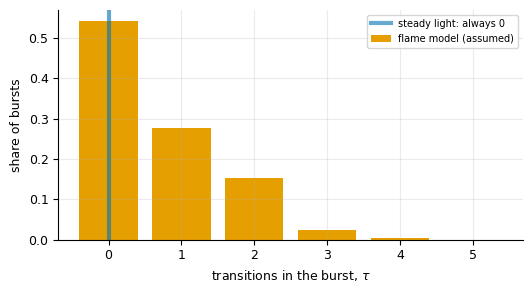

In [7]:
rng = random.Random(9)
M = 20000
tr_flame = [process(flame_burst(8, rng)).transitions for _ in range(M)]
det_flame = [process(flame_burst(8, rng)) for _ in range(M)]
print(f"{'tau_min':>8s} {'flame detected':>16s} {'steady light passes':>20s}   [flame = model]")
for tmin in range(0, 5):
    cfg = Config(flicker_min=tmin)
    fl = np.mean([process(flame_burst(8, rng), cfg).detected for _ in range(M)])
    st = process(steady_burst(8), cfg).detected
    print(f"{tmin:8d} {fl:16.3f} {str(st):>20s}")

fig, ax = plt.subplots(figsize=(5.4, 3.0))
vals, cnt = np.unique(tr_flame, return_counts=True)
ax.bar(vals, cnt / M, color="#e69f00", label="flame model (assumed)")
ax.axvline(0, color="#0072b2", lw=3, alpha=.6, label="steady light: always 0")
ax.set_xlabel("transitions in the burst, $\\tau$"); ax.set_ylabel("share of bursts"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading.** Under this flame model the flicker rule would be harmful: $\tau_{\min}=1$ already loses about two thirds of the detections of a real flame (0.81 down to 0.29 of the bursts), $\tau_{\min}=2$ about 85 % (down to 0.13). A burst of 8 reads taken 10 ms apart lasts only 80 ms, which is about one flicker period for a flame flickering near 10 Hz (a commonly quoted order of magnitude, not checked here), so few transitions can be expected in a burst whatever the flame does. The rule would need a much longer burst, several bursts per wake-up, or a different sensor output, and a recording of the real module to set it. **Decision for now:** the rule stays off ($\tau_{\min}=0$); the transition count is kept as an output for the recordings to come.

## 7. Summary and limits

| Question | Answer | Basis |
|---|---|---|
| Does the vote remove single glitches? | yes: at $p=0.1$ per read, 10 % of single reads become 0.04 % of bursts | exact formula, checked by simulation; **independent glitches assumed** |
| False suspicions per day from glitches (flame input alone) | none observed for $p\le 0.1$ (300 days Eco, 30 days Alert); a few at $p=0.2$ | simulation with the real state machine; **$p$ not measured** |
| Delay of a real flame | Eco: 5 to 10 min without recheck, 0.5 to 5.5 min with the 30 s recheck (mean 7.5 down to 3 min); Alert: 30 to 60 s | real state machine; hardware-wake timing not modelled |
| Steady light | passes the vote; protected only by the two-wake-up rule and the second witness; the recheck lets shorter glints through (2 min: 0 to 0.30 in Eco) | structure of the rules |
| Flicker rule | harmful under the assumed flame model; kept off | **flame model assumed** |

**What is not known.** The real output of the KY-026 under sunlight, in smoke, at distance and on a real flame (polarity, glitch rate, flicker, range, field of view, threshold potentiometer); the analogue output (not used); the burst length and spacing that the firmware can afford; the energy of a burst.

**Next steps.** Record the module outputs in the field (dark, sunlight, reflections, a lit candle or lighter at known distances) with bursts of 8 and longer; set the vote ratio and burst length on them; confirm with the team that the 30 s recheck (section 4) is worth its extra sensitivity to reflections (section 5).

**Project references.** Rules and tests: `ai-data/box/flame/FICHE.md`, `python/tests/` and `c/test/`; research log `docs/research/box-flame.md`; state machine `ai-data/box/state_machine/`.